In [1]:
#IMports needed for assignment
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
#Initialisation for the assignment such as the seed and data
Seed = 117
data_path = "/home/stefan_stringer/FinalSemester/Deep Learning/Advanced stat/Assignment/Second one/MexicoCovid19Data.csv"
PREDICTORS = ["SEX", "PATIENT_TYPE", "AGE", "ASTHMA", "TOBACCO"]

dataframe = pd.read_csv(data_path, index_col = 0)
dataframe

,SEX,PATIENT_TYPE,AGE,ASTHMA,TOBACCO,HAS_DIED
1,1,1,76,1,0,0
2,0,0,78,0,0,0
3,0,1,30,0,0,0
4,1,1,30,0,0,0
5,0,1,32,0,0,0
...,...,...,...,...,...,...
996,0,1,28,0,0,0
997,1,1,14,0,0,0
998,1,1,62,0,0,0
999,1,1,33,0,0,0


# A) Plot and summarise the data

## I want to summarise the data in a few points, so the first being the age of the patients, next will be mortality rates by the type of patient they are (Home or hospital), and finally

Text(0, 0.5, 'Mortality Rate')

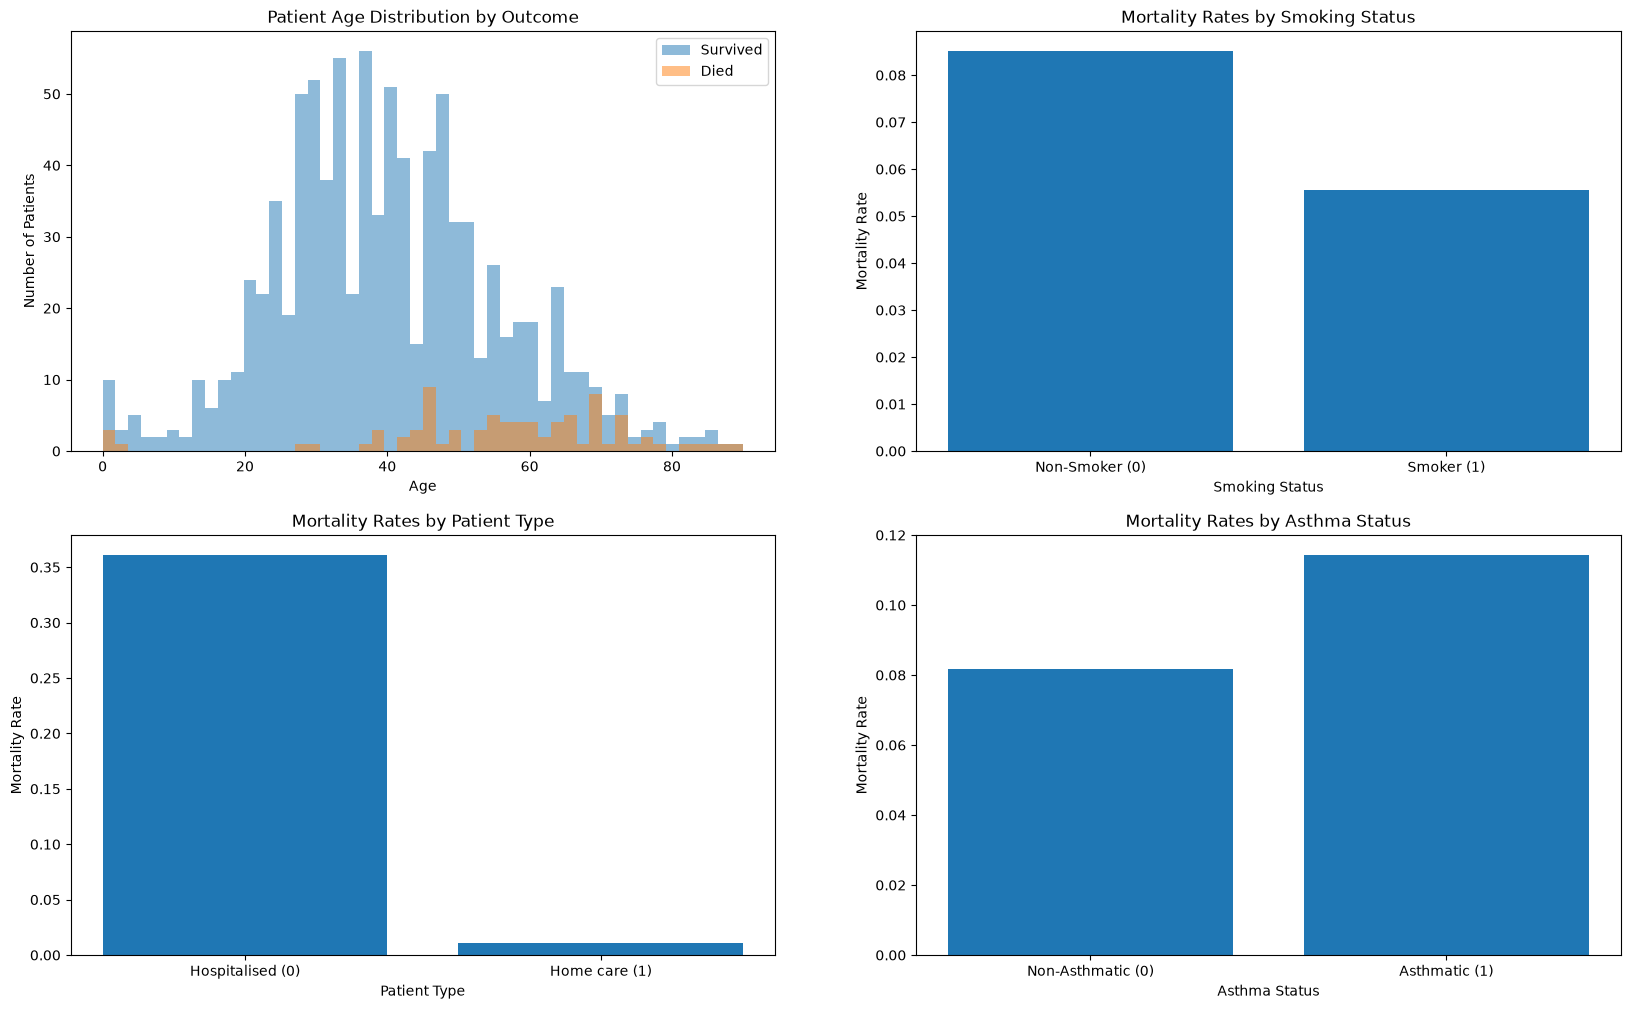

In [3]:
fig, axes = plt.subplots(2,2, figsize=(20, 12))

#First is patient age range:
for died, label in [(0, "Survived"), (1, "Died")]:
    axes[0,0].hist(dataframe[dataframe["HAS_DIED"] == died]["AGE"], bins=50, alpha=0.5, label=label)

axes[0,0].set_title("Patient Age Distribution by Outcome")
axes[0,0].set_xlabel("Age")
axes[0,0].set_ylabel("Number of Patients")
axes[0,0].legend()

#Second is mortality rates by patient type:
mortality_rates = dataframe.groupby("PATIENT_TYPE")["HAS_DIED"].mean()
axes[1,0].bar(["Hospitalised (0)", "Home care (1)"], mortality_rates.values)
axes[1,0].set_title("Mortality Rates by Patient Type")
axes[1,0].set_xlabel("Patient Type")
axes[1,0].set_ylabel("Mortality Rate")

#Third is mortality rates by patient being a smoker vs non smoker:
mortality_rates_smoker = dataframe.groupby("TOBACCO")["HAS_DIED"].mean()
axes[0,1].bar(["Non-Smoker (0)", "Smoker (1)"], mortality_rates_smoker.values)
axes[0,1].set_title("Mortality Rates by Smoking Status")
axes[0,1].set_xlabel("Smoking Status")
axes[0,1].set_ylabel("Mortality Rate")

#Fourth is mortality rates by patient being asthematic vs non asthmatic:
mortality_rates_asthma = dataframe.groupby("ASTHMA")["HAS_DIED"].mean()
axes[1,1].bar(["Non-Asthmatic (0)", "Asthmatic (1)"], mortality_rates_asthma.values)
axes[1,1].set_title("Mortality Rates by Asthma Status")
axes[1,1].set_xlabel("Asthma Status")
axes[1,1].set_ylabel("Mortality Rate")


# (b) Apply the casl_glm_nr_logistic() function from CASL page 127 to estimate the parameters in
# a standard logistic regression model for the data. Interpret the estimated coefficients of the model.
# Make sure (and argue why) your interpretation and the selected plots in (a) are in accordance.


In [4]:
def sigmoid(z):
    out = np.empty_like(z, dtype=float)
    pos = z >= 0
    out[pos] = 1.0 / (1.0 + np.exp(-z[pos]))
    ez = np.exp(z[~pos])
    out[~pos] = ez / (1.0 + ez)
    return out

#function found in book with code for R, page 127, with translation to make into python as I prefer python to R
# casl_glm_nr_logistic <-
#   function(X, y, maxit = 25L, tol = 1e-10)
#   {
#     beta <- rep(0, ncol(X))                           same as: beta = np.zeros(X.shape[1])
#     for (j in seq(1L, maxit))
#     {
#       b_old <- beta
#       p <- 1 / (1 + exp(- X %*% beta))               same as: prob = sigmoid(X @ beta)
#       W <- as.numeric(p * (1 - p))                 same as: w = prob * (1 - prob)
#       XX <- crossprod(X, diag(W) %*% X)            same as info = X.T @ (X * w[:, None]) #Had to use assitance on this line
#       score <- t(X) %*% (y - p)                    same as: score = X.T @ (y - prob)
#       delta <- solve(XX, score)                     is just np.linalg.solve(info, score)
#       beta <- beta + delta                          left as exercise for reader as easy
#       if (sqrt(crossprod(beta - b_old)) < tol) break      its an if statement under tolerance for sqrt(sum((beta - beta_old) ** 2))
#     }
#     beta
#   }
def nr_logistic(X, y, lam=0.0, max_iter=25, tolerance=1e-10):
    beta = np.zeros(X.shape[1])
    pen = np.ones(X.shape[1])
    pen[0] = 0.0
    P = np.diag(pen)

    for _ in range(max_iter):
        beta_old = beta.copy()
        prob = sigmoid(X @ beta)
        w = prob * (1 - prob)
        score = X.T @ (y - prob) - lam * (P @ beta) #adding the lambda here incoporates the ridge regression penalty into the score calculation
        info = X.T @ (X * w[:, None]) + lam * P #same here. Otherwise if 0, this element does nothing! easy implementation
        delta = np.linalg.solve(info, score)
        beta = beta + delta

        if np.sqrt(((beta - beta_old) ** 2).sum()) < tolerance:
            break
    return beta


#I got help with how to do this, as this was something that really held me up for a bit.
# However making it a dataframe was much easier, as I am used to working with pandas in python
def make_design_matrix(df):
    intercept     = np.ones(len(df))
    sex           = df.SEX.to_numpy(float)
    patient_type  = df.PATIENT_TYPE.to_numpy(float)
    age           = df.AGE.to_numpy(float)
    asthma        = df.ASTHMA.to_numpy(float)
    tobacco       = df.TOBACCO.to_numpy(float)
    y             = df.HAS_DIED.to_numpy(float)

    X = np.column_stack([intercept, sex, patient_type, age, asthma, tobacco])
    names = ["intercept", "SEX", "PATIENT_TYPE", "AGE", "ASTHMA", "TOBACCO"]
    return X, y, names


X, y, names = make_design_matrix(dataframe)
beta_std = nr_logistic(X, y)
beta_std

array([-1.9190826 , -0.71255164, -3.57751436,  0.03101216,  0.83113579,
       -0.48945714])

In [5]:
results = pd.DataFrame({"Coefficient": beta_std}, index=names)
results

,Coefficient
intercept,-1.919083
SEX,-0.712552
PATIENT_TYPE,-3.577514
AGE,0.031012
ASTHMA,0.831136
TOBACCO,-0.489457


In [6]:
# The odds ratio is the exponent of the coefficient. This comes from the fact that the logistic regression model is log-odds,
# so taking exponent on each side the coefficients gives us the odds ratios.
#https://en.wikipedia.org/wiki/Logistic_regression
results["Odds Ratio"] = np.exp(results["Coefficient"])
results

,Coefficient,Odds Ratio
intercept,-1.919083,0.146742
SEX,-0.712552,0.490391
PATIENT_TYPE,-3.577514,0.027945
AGE,0.031012,1.031498
ASTHMA,0.831136,2.295925
TOBACCO,-0.489457,0.612959


## Write up for logistic regression models coefficients, and the plots shown:

The four plots I did previously started from the most intuitive thing to look at, the survival/death distribution of the data based by age. Showing that there is an unfortunate number of very young, and an unsurprising number of middle age to older people, with 20s and 30s mostly uneffected.

From this the natural progression in my head, was looking at the mortality rates for patient type, and both smoking and asthma, considering that peoples respitory issues could contribute.

So I clearly did this in python, and got the above coefficients.

The obvious one being patient type, which seems rather obvious. If you are admitted to hospital, it must be serious, so a funny one to make a conclusion from.

Next, Asthmatics had a higher rate of mortality than non-asthmatics, This was also expected.

Smoking was surprisingly low on the mortality scale. I dont really know why this the case?

Also age, as in the plot, was significant the older you get. Its fair to say that there is an increase for each year, as the older you are, the higher chance of death (also visually seen)

My intercept, (Come back to this later)

## 

## (c) Derive the Newton-Raphson algorithm for logistic regression with a ridge penalty, and modify the
## CASL implementation of standard logistic regression to logistic regression with a ridge penalty

In [8]:
#Main difference between ridge and standard is that our lambda value must be higher than zero
#This is added as an input, and the function was made such that adding this will work as needed
beta_ridge = nr_logistic(X, y, lam=10)
beta_ridge

array([-3.06123142, -0.38581864, -1.8591949 ,  0.04103236,  0.13067022,
       -0.10353963])

In [9]:
results_ridge = pd.DataFrame({"Coefficient": beta_ridge}, index=names)
results_ridge["Odds Ratio"] = np.exp(results_ridge["Coefficient"])
results_ridge

,Coefficient,Odds Ratio
intercept,-3.061231,0.046830
SEX,-0.385819,0.679894
PATIENT_TYPE,-1.859195,0.155798
AGE,0.041032,1.041886
ASTHMA,0.130670,1.139592
TOBACCO,-0.103540,0.901640


In [10]:
results_ridge["coefficient difference"] = results_ridge["Coefficient"] - results["Coefficient"]
results_ridge

,Coefficient,Odds Ratio,coefficient difference
intercept,-3.061231,0.046830,-1.142149
SEX,-0.385819,0.679894,0.326733
PATIENT_TYPE,-1.859195,0.155798,1.718319
AGE,0.041032,1.041886,0.010020
ASTHMA,0.130670,1.139592,-0.700466
TOBACCO,-0.103540,0.901640,0.385918


It seems as though here everything but age went down in terms of how much it contributed to deaths.
Age is clearly important, and a high contributer. However being asthematic and smoking were things that shrinked a lot? This really surpises me.
The intercept moved a lot too, maybe because it was penalised before so here it can move where ever to keep the death rate? This was a surprising result, that it couldnt reduce some covariants to zero, and gave this.

## (d) Use your implementation to analyze the data using logistic regression with a ridge penalty. The
## tuning parameter for the ridge penalty should be estimated using k-fold cross-validation where
## k > 1. Compare the ridge coefficients to the coefficients from the standard model.


In [11]:
# https://www.geeksforgeeks.org/machine-learning/stratified-k-fold-cross-validation/
# and https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedKFold.html
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import log_loss

k = 10
lambdas = np.logspace(-4, 4, 50) #for now we pick 10 differet values
folds = StratifiedKFold(n_splits=k, shuffle=True, random_state=Seed)

cvloss = []

for l in lambdas:
    foldLoss = []
    for train_idx, value_idx in folds.split(X, y):
        beta_fold = nr_logistic(X[train_idx], y[train_idx], lam=l) #do ridge here with each lambda we have
        prob_fold = sigmoid(X[value_idx] @ beta_fold)
        foldLoss.append(log_loss(y[value_idx], prob_fold))
    cvloss.append(np.mean(foldLoss))


cvloss = np.array(cvloss)
best_lambda = lambdas[int(np.argmin(cvloss))]
best_lambda


np.float64(1.2067926406393288)

Note, for 10 values of lambda, the best that it picked was 0.35
for 25, it was 1.0

so we did for 50 to get more points on plot

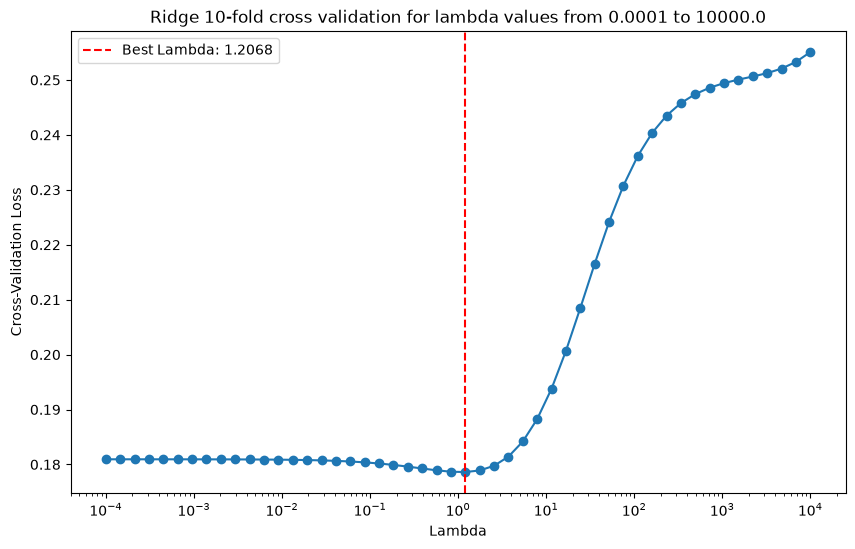

In [12]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(lambdas, cvloss, marker='o')
ax.axvline(x=best_lambda, color='r', linestyle='--', label=f'Best Lambda: {best_lambda:.4f}')
ax.set_xscale('log')
ax.set_xlabel('Lambda')
ax.set_ylabel('Cross-Validation Loss')
ax.set_title(f'Ridge 10-fold cross validation for lambda values from {lambdas[0]} to {lambdas[-1]}')
plt.legend()
plt.show()

In [13]:
beta_ridge_best = nr_logistic(X, y, lam=best_lambda)

comparison_df = pd.DataFrame({
    "standard_model": beta_std,
    "ridge_model": beta_ridge_best
}, index=names)

comparison_df["coefficient_difference"] = comparison_df["ridge_model"] - comparison_df["standard_model"]
comparison_df

,standard_model,ridge_model,coefficient_difference
intercept,-1.919083,-2.128296,-0.209213
SEX,-0.712552,-0.624937,0.087615
PATIENT_TYPE,-3.577514,-3.111223,0.466291
AGE,0.031012,0.032691,0.001679
ASTHMA,0.831136,0.516537,-0.314599
TOBACCO,-0.489457,-0.326746,0.162711


Everything here shrunk an amount, except for age! That increased, again as we all remember, it affected older people so much more, so this makes sense in my eyes at least.

## (e) Now consider logistic regression with a lasso penalty. Derive a combined Newton-Raphson and
## Majorize-Minimize algorithm for penalized maximum likelihood estimation of the coefficients in
## the model. Modify the CASL implementation of standard logistic regression to logistic regression
## with a lasso penalty.


I wrote this out on paper, but have placed the important parts here as the feedback I got last time was fair.
The difference with Lasso and Ridge is that Lasso can shrink the coefficints to zero, which can be useful. This is because the coefficient vector is absolute value, and not squared like Ridge is:
$$
\lambda \sum_{j=1}^{p}|\beta_j|
$$

SO i need to logistic regression model which is,

$$
p_i=P(Y_i=1|X_i)
=\frac{1}{1+\exp(-X_i^T\beta)}
$$
and its log likelihood for it being (https://en.wikipedia.org/wiki/Logistic_regression),

$$
\ell(\beta)=
\sum_{i=1}^{n}
\left[
y_i\log(p_i)+(1-y_i)\log(1-p_i)
\right]
$$


To add the lasso into it, it is subtracted from the log likelihood. From there, the negative log likelihood is taken as its this we want to minimise. This gives,

$$
Q(\beta)=
-\ell(\beta)+\lambda\sum_{j=1}^{p}|\beta_j|
$$

Fully writting this out but substituing the negative log likelihood gives the function that the coefficient vector, $\beta$, wants to minimise.

$$
Q(\beta)=
\sum_{i=1}^{n}
\left[
\log(1+\exp(X_i^T\beta))
-y_iX_i^T\beta
\right]
+\lambda\sum_{j=1}^{p}|\beta_j|
$$

I really struggled with this step, as Lasso is not differentiable everywhere. So getting the Majorise-Minimise approximation is not straightforward. After a lot of assistance, the tip was to replace the function with a simpler one. For an absolute function, the inequality can be ustalised so long as $ x_0 \neq 0 $ ,

$$
|x|\leq
\frac{x_{t}^2}{2|x_{t-1}|}+\frac{|x_{t-1}|}{2}
$$

Inserting this inequality helps solve the issue of differentiability, trying to follow the notation throughout the course, where the iteration step t is up top, (due to formatting if there is no t, that is current step, so t is actually $t-1$) and j is below, we insert and get the following,

$$
\lambda\sum_{j=1}^{p}|\beta_j|
\leq
\frac{\lambda}{2}
\sum_{j=1}^{p}
\frac{\beta_j^2}{|\beta_j^{(t)}|}
+
\frac{\lambda}{2}
\sum_{j=1}^{p}|\beta_j^{(t)}|
$$


The final term with absolute value $\beta_j^{(t)}$ is a constant when considering the new coeeficceint estimates, so this can be ignored.

$$
Q_{\text{MM}}(\beta|\beta^{(t)})
=
-\ell(\beta)
+
\frac{\lambda}{2}
\sum_{j=1}^{p}
\frac{\beta_j^2}{|\beta_j^{(t)}|}
+
\frac{\lambda}{2}
\sum_{j=1}^{p}|\beta_j^{(t)}|
=
-\ell(\beta)
+
\frac{\lambda}{2}
\sum_{j=1}^{p}
\frac{\beta_j^2}{|\beta_j^{(t)}|}
$$

now there is a weighted penalty for the lasso term which is,
$$
\omega_j = \frac{1}{|\beta_j^{(t)}|}
$$

Getting this in matrix notation, which will help with the maths later in python, the approximation can be a diagonal matrix, with these terms along it.
This can be then rewritten in trhe following notation, with D being the diagonal matrix, and the $\beta$ being the coefficients,

$$
Q_{\text{MM}}(\beta|\beta^{(t)})
=
-\ell(\beta)
+\frac{\lambda}{2}\beta^TD^{(t)}\beta
$$

This is similar to the ridge one, however that had a fixed matrix P, which was implemented earlier but seen in the following equation:

$$
Q_{\text{Ridge}}(\beta)
=
-\ell(\beta)
+\frac{\lambda}{2}\beta^TP\beta

I now need to take the gradient, as I have this in matrix notaiton.
So,

$$
\nabla Q_{\text{MM}}
=
\nabla(-\ell(\beta))
+
\nabla\left(
\frac{\lambda}{2}\beta^TD^{(t)}\beta
\right)
=
X^T(p-y)+\lambda D^{(t)}\beta

$$
Again, I have inserted the terms as final results as this also took a while. However, this results in the gradianet needed for the Newton Raphson optimisation step.
The next part is to differentiate the gradient with respect to the coefficient vector, which is also a fair amount, but essentially we take the gradient again on what we had. This is written as,

$$
\nabla^2 Q_{\text{MM}}
=
\nabla^2(-\ell(\beta))
+
\nabla^2\left(
\frac{\lambda}{2}\beta^TD^{(t)}\beta
\right)
=
\nabla( X^T(p-y))+\nabla (\lambda D^{(t)}\beta)
$$

this gives,

$$
H = X^T \text{diag}(p_i(1-p_i)) X + \lambda D^{(t)}
$$

which is the Hessian matrix as described here https://en.wikipedia.org/wiki/Newton%27s_method_in_optimization, and shown for higher dimensions.

Therefore using what is written there, the update can be written as:

$$
\beta_{new} = \beta_{old} - H^{-1} \nabla Q_{MM}
$$

Which are all the elements we now have, so inserting this gives,

$$
\beta_{new} = \beta_{old} -(X^T \text{diag}(p_i(1-p_i)) X + \lambda D^{(t)})^{-1} (X^T(p-y)+\lambda D^{(t)}\beta)
$$

This is actually really close to what I implemented earlier, hwoever again, the Ridge method had a fixed penalty matrix P, whereas the matrix $D^{(t)}$ can actually update with each step.
So this shouldnt be too hard to implement in the next part.

In [14]:
##I was going to make it all in the same function, but I didnt want to do checks and all. It is so close to the same code, so there is really just some small
# changes to make on the original function, having the MM convergence there too



def nr_lasso_logistic(X, y, lam=1.0, max_outer=100, max_inner=100, tolerance=1e-8, epsilon=1e-6):
    beta = nr_logistic(X, y)
    pen = np.ones(X.shape[1])
    pen[0] = 0.0
    for _ in range(max_outer):
        beta_old = beta.copy()
        #This is to change the P to the matrix D
        weights = pen / np.maximum(np.abs(beta), epsilon)
        D = np.diag(weights) #so too here, as P isnt needed, we used D the diagonal of weights
        for _ in range(max_inner): 
            beta_inner_old = beta.copy()
            prob = sigmoid(X @ beta)
            w = prob * (1 - prob)
            score = X.T @ (y - prob) - lam * (D @ beta)
            info = X.T @ (X * w[:, None]) + lam * D
            delta = np.linalg.solve(info, score)
            beta = beta + delta
            if np.linalg.norm(beta - beta_inner_old) < tolerance:
                break
        if np.linalg.norm(beta - beta_old) < tolerance:
            break

    return beta

In [15]:
beta_lasso = nr_lasso_logistic(X, y, lam = 10)
beta_lasso

array([-2.67938883e+00, -2.06132643e-06, -2.54340895e+00,  3.54244185e-02,
        1.35573957e-07, -1.09352028e-07])

In [16]:
results_lasso = pd.DataFrame( {"Coefficient": beta_lasso}, index=names)
results_lasso["Odds Ratio"] = np.exp(results_lasso["Coefficient"])
results_lasso

,Coefficient,Odds Ratio
intercept,-2.679389e+00,0.068605
SEX,-2.061326e-06,0.999998
PATIENT_TYPE,-2.543409e+00,0.078598
AGE,3.542442e-02,1.036059
ASTHMA,1.355740e-07,1.000000
TOBACCO,-1.093520e-07,1.000000


## (f) Use your implementation to analyze the data using logistic regression with a lasso penalty. The
## tuning parameter for the lasso penalty should be estimated using cross-validation. Compare the
## lasso coefficients to the coefficients from the standard and the ridge model.

In [17]:
cv = StratifiedKFold(n_splits=k, shuffle=True, random_state=Seed)

lams = np.logspace(-4, 4, 50)
lasso_cvloss = []

In [18]:
for l in lams:

    fold_Loss = []

    for train_index, val_index in cv.split(X, y):
        beta_lasso = nr_lasso_logistic(X[train_index], y[train_index], lam=l)
        p_val = sigmoid(X[val_index] @ beta_lasso)
        error = log_loss(y[val_index], p_val)

        fold_Loss.append(error)

    lasso_cvloss.append(np.mean(fold_Loss))
    
lasso_fold_loss = np.array(lasso_cvloss)
best_lcv_lambda = lams[int(np.argmin(lasso_fold_loss))]
best_lcv_lambda

np.float64(2.559547922699533)

OKay this was a different value to ridge, but it makes sense as some can be set to 0!

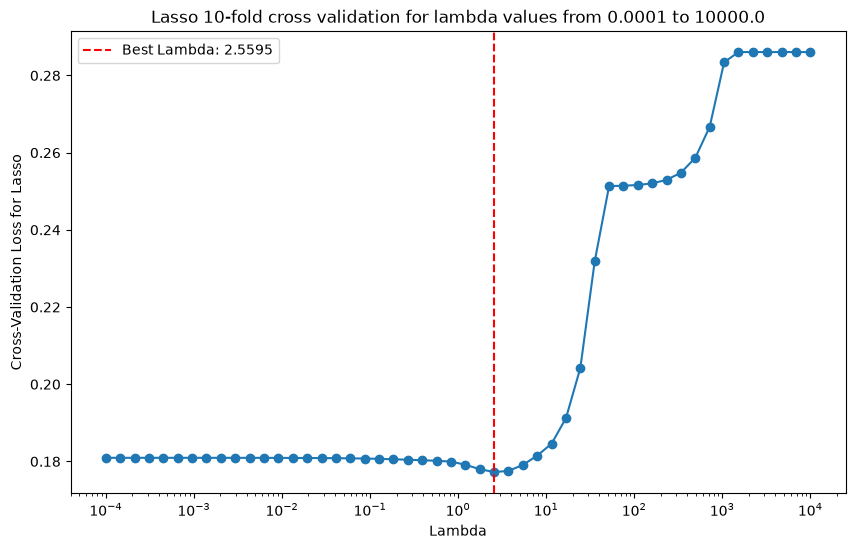

In [19]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(lams, lasso_cvloss, marker='o')
ax.axvline(x=best_lcv_lambda, color='r', linestyle='--', label=f'Best Lambda: {best_lcv_lambda:.4f}')
ax.set_xscale('log')
ax.set_xlabel('Lambda')
ax.set_ylabel('Cross-Validation Loss for Lasso')
ax.set_title(f'Lasso 10-fold cross validation for lambda values from {lams[0]} to {lams[-1]}')
plt.legend()
plt.show()

In [21]:
#Here is the fit for the best lambda given

beta_lasso = nr_lasso_logistic(X, y, lam = best_lcv_lambda)
beta_lasso

array([-2.09894533e+00, -4.51184569e-01, -3.24879134e+00,  3.14367998e-02,
        6.03943694e-07, -5.11414748e-07])

In [23]:
results_lasso = pd.DataFrame({"coefficient": beta_lasso}, index = names)
results_lasso["odds ratio"] = np.exp(results_lasso["coefficient"])
results_lasso

,coefficient,odds ratio
intercept,-2.098945e+00,0.122586
SEX,-4.511846e-01,0.636873
PATIENT_TYPE,-3.248791e+00,0.038821
AGE,3.143680e-02,1.031936
ASTHMA,6.039437e-07,1.000001
TOBACCO,-5.114147e-07,0.999999


In [26]:
comparison_df = pd.DataFrame({"Standard": beta_std, "Ridge": beta_ridge, "Lasso": beta_lasso}, index=names)
comparison_df

,Standard,Ridge,Lasso
intercept,-1.919083,-3.061231,-2.098945e+00
SEX,-0.712552,-0.385819,-4.511846e-01
PATIENT_TYPE,-3.577514,-1.859195,-3.248791e+00
AGE,0.031012,0.041032,3.143680e-02
ASTHMA,0.831136,0.130670,6.039437e-07
TOBACCO,-0.489457,-0.103540,-5.114147e-07


In [ ]:
fig, ax = plt.subplots(figsize=(10, 8))
comparison_df.plot(kind='bar', ax = ax)
ax.axline(y= 0, color = 'k')
ax.set_xlabel('preds')
ax.set_ylabel('estimated coefficeints')
ax.set_title